# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [ ]:
%cd /content/K4-Track-4-Day10-VisionLanguageModel
from pathlib import Path

for name in ("E1", "E2", "E3"):
    print(
        name,
        "run local:", (Path("work") / name / "run.json").exists(),
        "evidence:", (Path("report/evidence") / f"{name.lower()}.json").exists(),
    )

/content/K4-Track-4-Day10-VisionLanguageModel
E1 run local: True evidence: True
E2 run local: True evidence: False
E3 run local: False evidence: False


In [1]:
# Colab starts in /content; clone the public fork so scripts and configs are available.
from pathlib import Path
import subprocess

REPO_DIR = Path("/content/K4-Track-4-Day10-VisionLanguageModel")
REPO_URL = "https://github.com/Duytd26/K4-Track-4-Day10-VisionLanguageModel.git"
if not (REPO_DIR / ".git").exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
%cd /content/K4-Track-4-Day10-VisionLanguageModel


/content/K4-Track-4-Day10-VisionLanguageModel


In [2]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L
!pip -q install -r requirements-colab.txt
# Colab can preinstall torchao 0.10.0; PEFT 0.21.2 rejects it. This lab uses BitsAndBytes NF4.
!pip -q uninstall -y torchao
import importlib.util
assert importlib.util.find_spec("torchao") is None, "Restart runtime after removing torchao, then rerun setup cells."

GPU 0: Tesla T4 (UUID: GPU-6642a130-7203-fc6d-40b6-813a61afca50)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 114.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.3 MB/s eta 0:00:00


In [ ]:
# Run the assignment integrity checks before downloading data.
!python -m pytest -q


...........................s.........................................    [100%]
68 passed, 1 skipped in 1.39s


In [4]:
# Mount Drive so adapters and checkpoints survive Colab restarts.
from pathlib import Path
import shutil
from google.colab import drive

drive.mount("/content/drive")
DRIVE_RUNS = Path("/content/drive/MyDrive/day10-vlm/runs")
DRIVE_RUNS.mkdir(parents=True, exist_ok=True)
DRIVE_ARTIFACTS = Path("/content/drive/MyDrive/day10-vlm/artifacts")
DRIVE_ARTIFACTS.mkdir(parents=True, exist_ok=True)

def backup_artifact(relative_path):
    source = Path(relative_path)
    assert not source.is_absolute(), source
    assert source.is_file(), f"Missing artifact: {source}"
    destination = DRIVE_ARTIFACTS / source
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)
    return destination

def restore_artifact(relative_path):
    destination = Path(relative_path)
    assert not destination.is_absolute(), destination
    source = DRIVE_ARTIFACTS / destination
    assert source.is_file(), f"No Drive backup: {source}"
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)
    return destination

print(f"Checkpoints: {DRIVE_RUNS}; predictions/evidence: {DRIVE_ARTIFACTS}")


Mounted at /content/drive
Checkpoints: /content/drive/MyDrive/day10-vlm/runs; predictions/evidence: /content/drive/MyDrive/day10-vlm/artifacts


In [6]:
# Kaggle: dùng Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY). KHÔNG viết khoá vào notebook.
import os
from google.colab import userdata
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

## 1. Dữ liệu: tải và chia split

In [7]:
!python scripts/prepare_data.py --kaggle

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:00<00:00, 341MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


dataset_version: d10-21e4070301
split  images  pothole  crack  manhole  sessions
train    1422     1074   1750      691        13
val       276       66    470      103         2
test      311      121    299      163         3
Session sets are disjoint across train/val/test.


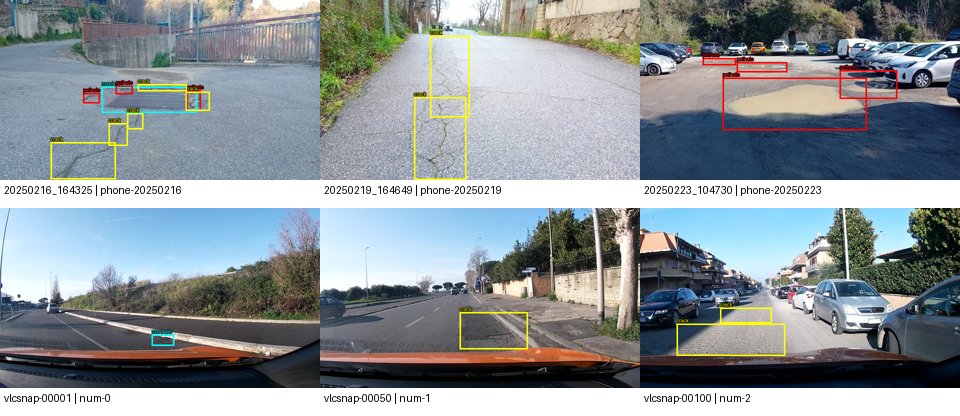

In [8]:
# Verify the fixed session split, compare counts, and inspect six labeled training images.
import json
from collections import Counter
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
from scripts.labcommon import read_jsonl

DATA_ROOT = Path("data")
SPLIT_DIR = DATA_ROOT / "splits"
with (SPLIT_DIR / "meta.json").open(encoding="utf-8") as f:
    split_meta = json.load(f)
dataset_version = split_meta["dataset_version"]
assert dataset_version.startswith("d10-"), dataset_version

expected = {
    "train": {"images": 1422, "boxes": {"pothole": 1074, "crack": 1750, "manhole": 691}},
    "val":   {"images": 276,  "boxes": {"pothole": 66,   "crack": 470,  "manhole": 103}},
    "test":  {"images": 311,  "boxes": {"pothole": 121,  "crack": 299,  "manhole": 163}},
}
split_rows = {s: read_jsonl(SPLIT_DIR / f"{s}.jsonl") for s in ("train", "val", "test")}
split_sessions = {s: {r["session"] for r in rows} for s, rows in split_rows.items()}
for s, rows in split_rows.items():
    image_count = len(rows)
    box_counts = Counter(o["label"] for r in rows for o in r["objects"])
    assert image_count == expected[s]["images"], (s, image_count)
    assert dict(box_counts) == expected[s]["boxes"], (s, dict(box_counts))
    assert split_meta["counts"][s]["images"] == image_count
    assert split_meta["counts"][s]["boxes"] == dict(box_counts)
    assert all(split_meta["groups"].get(session) == s for session in split_sessions[s])
for left, right in (("train", "val"), ("train", "test"), ("val", "test")):
    overlap = split_sessions[left] & split_sessions[right]
    assert not overlap, f"Session leakage between {left} and {right}: {sorted(overlap)[:5]}"

print(f"dataset_version: {dataset_version}")
print("split  images  pothole  crack  manhole  sessions")
for s, rows in split_rows.items():
    c = split_meta["counts"][s]["boxes"]
    print(f"{s:5}  {len(rows):6}  {c['pothole']:7}  {c['crack']:5}  {c['manhole']:7}  {len(split_sessions[s]):8}")
print("Session sets are disjoint across train/val/test.")

train_samples = split_rows["train"]
colors = {"pothole": "red", "crack": "yellow", "manhole": "cyan"}
chosen, used_sessions = [], set()
for row in sorted(train_samples, key=lambda r: r["image_id"]):
    if row["session"] not in used_sessions and row["objects"]:
        chosen.append(row)
        used_sessions.add(row["session"])
    if len(chosen) == 6:
        break
assert len(chosen) == 6, "Need six labeled training images from distinct sessions."

tile_w, tile_h, caption_h = 320, 180, 28
canvas = Image.new("RGB", (tile_w * 3, (tile_h + caption_h) * 2), "white")
for i, row in enumerate(chosen):
    img = Image.open(DATA_ROOT / row["image_path"]).convert("RGB")
    draw = ImageDraw.Draw(img)
    W, H = img.size
    assert (W, H) == (row["width"], row["height"])
    for obj in row["objects"]:
        xc, yc, bw, bh = obj["yolo"]
        x1 = max(0, min(W - 1, round((xc - bw / 2) * W)))
        y1 = max(0, min(H - 1, round((yc - bh / 2) * H)))
        x2 = max(0, min(W - 1, round((xc + bw / 2) * W)))
        y2 = max(0, min(H - 1, round((yc + bh / 2) * H)))
        color = colors[obj["label"]]
        draw.rectangle((x1, y1, x2, y2), outline=color, width=3)
        draw.text((x1, max(0, y1 - 12)), obj["label"], fill=color, stroke_width=1, stroke_fill="black")
    img = img.resize((tile_w, tile_h))
    x = (i % 3) * tile_w
    y = (i // 3) * (tile_h + caption_h)
    canvas.paste(img, (x, y))
    caption = f"{row['image_id']} | {row['session']}"
    ImageDraw.Draw(canvas).text((x + 4, y + tile_h + 4), caption, fill="black")
display(canvas)


## 2. Nhãn: YOLO → JSON thang 0–1000

YOLO boxes store normalized center and size. Convert each edge to the shared 0-1000 scale, then sort boxes by `(y1, x1)` so target JSON order is stable. Empty annotations become `[]`.

The E0 section below loads the frozen base model in NF4, generates one raw completion for every test image, writes `work/e0.jsonl`, and scores it with the provided script.


In [9]:
# Convert YOLO labels into deterministic Qwen grounding JSON on the 0-1000 scale.
import json
from scripts.labcommon import CLASSES, read_jsonl


def yolo_to_box(label: str, yolo: list[float]) -> dict:
    if label not in CLASSES:
        raise ValueError(f"Unknown class: {label}")
    xc, yc, w, h = yolo
    coords = [
        round(max(0.0, min(1000.0, (xc - w / 2) * 1000))),
        round(max(0.0, min(1000.0, (yc - h / 2) * 1000))),
        round(max(0.0, min(1000.0, (xc + w / 2) * 1000))),
        round(max(0.0, min(1000.0, (yc + h / 2) * 1000))),
    ]
    x1, y1, x2, y2 = coords
    if x2 <= x1:
        if x1 < 1000:
            x2 = x1 + 1
        else:
            x1 = 999
    if y2 <= y1:
        if y1 < 1000:
            y2 = y1 + 1
        else:
            y1 = 999
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}


def objects_to_answer(objects: list[dict]) -> str:
    boxes = [yolo_to_box(obj["label"], obj["yolo"]) for obj in objects]
    boxes.sort(key=lambda box: (box["bbox_2d"][1], box["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"))

PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output only a JSON list of objects with label and bbox_2d coordinates "
    "normalized on a 0-1000 scale: "
    '[{"label":"pothole","bbox_2d":[x1,y1,x2,y2]}]. '
    "If no damage is found, output []."
)

# Inspect one converted answer without needing to load the model.
_example = next(row for row in split_rows["train"] if row["objects"])
print("Example target:", objects_to_answer(_example["objects"]))


Example target: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]


## 3. E0: zero-shot

In [10]:
# Load the untouched Qwen3-VL base model for the E0 zero-shot baseline.
import gc
import json
from pathlib import Path

import torch
from PIL import Image
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration
from scripts.labcommon import read_jsonl

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"
assert torch.cuda.is_available(), "Select a Colab GPU runtime before loading the model."
quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=["model.visual", "lm_head"],
)
model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization,
    dtype=torch.float16,
    device_map={"": 0},
)
from bitsandbytes.nn import Linear4bit
quantized_visual = [
    name for name, module in model.named_modules()
    if name.startswith("model.visual.") and isinstance(module, Linear4bit)
]
assert not quantized_visual, f"ViT was quantized despite the skip list: {quantized_visual[:5]}"
assert not isinstance(model.lm_head, Linear4bit), "lm_head was quantized despite the skip list."
model.eval()
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "left"

test_rows = read_jsonl("data/splits/test.jsonl")
assert len(test_rows) == 311, f"Expected 311 test images, found {len(test_rows)}"
BATCH_SIZE = 4
MAX_NEW_TOKENS = 256
pred_path = Path("work/e0.jsonl")
pred_path.parent.mkdir(parents=True, exist_ok=True)

with pred_path.open("w", encoding="utf-8") as pred_file:
    for start in range(0, len(test_rows), BATCH_SIZE):
        batch = test_rows[start:start + BATCH_SIZE]
        images, conversations = [], []
        for row in batch:
            with Image.open(Path("data") / row["image_path"]) as im:
                image = im.convert("RGB")
            images.append(image)
            conversations.append([{
                "role": "user",
                "content": [
                    {"type": "image", "image": image},
                    {"type": "text", "text": PROMPT},
                ],
            }])
        inputs = processor.apply_chat_template(
            conversations,
            tokenize=True,
            add_generation_prompt=True,
            return_dict=True,
            return_tensors="pt",
            padding=True,
        ).to(model.device)
        inputs.pop("token_type_ids", None)
        with torch.inference_mode():
            generated = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        completion_ids = generated[:, inputs["input_ids"].shape[1]:]
        raw_outputs = processor.batch_decode(
            completion_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )
        for row, raw in zip(batch, raw_outputs):
            pred_file.write(json.dumps({"image_id": row["image_id"], "raw": raw}, ensure_ascii=False) + "\n")
        pred_file.flush()
        backup_artifact(pred_path)
        print(f"E0 predictions: {min(start + len(batch), len(test_rows))}/{len(test_rows)}")
        del images, conversations, inputs, generated, completion_ids, raw_outputs
        torch.cuda.empty_cache()

assert pred_path.exists() and pred_path.stat().st_size > 0
print(f"Saved raw E0 predictions to {pred_path}")
# Release VRAM before the later training cells; keep the lightweight processor.
del model
gc.collect()
torch.cuda.empty_cache()


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

E0 predictions: 300/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E0 predictions: 304/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E0 predictions: 308/311
E0 predictions: 311/311
Saved raw E0 predictions to work/e0.jsonl


In [11]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json
backup_artifact("report/evidence/e0.json")
print("E0 evidence saved to Drive.")

E0 [test] n=311 valid=0.894 P=0.141 R=0.072 F1=0.095 CI95=0.067-0.125 meanIoU=0.603 FP/img=0.82
   pothole  P=0.244 R=0.083 F1=0.123
   crack    P=0.038 R=0.023 F1=0.029
   manhole  P=0.342 R=0.153 F1=0.212
E0 evidence saved to Drive.


In [12]:
# Read the official score and inspect raw model behavior for the report.
import json
from scripts.labcommon import read_jsonl

with open("report/evidence/e0.json", encoding="utf-8") as f:
    e0_result = json.load(f)
assert e0_result["score_version"] == 1
assert e0_result["split"] == "test"
assert e0_result["n_images"] == 311
assert e0_result["missing_predictions"] == 0
assert e0_result["dataset_version"] == dataset_version
print(f"E0 parse_valid_rate: {e0_result['parse_valid_rate']:.3f}")
print(f"E0 micro F1: {e0_result['micro']['f1']:.3f}")
print("First five raw completions:")
for pred in read_jsonl("work/e0.jsonl")[:5]:
    print(pred["image_id"], repr(pred["raw"]))


E0 parse_valid_rate: 0.894
E0 micro F1: 0.095
First five raw completions:
vlcsnap-00200 '[{"label":"manhole","bbox_2d": [770, 640, 843, 687]}]'
vlcsnap-00201 '[]'
vlcsnap-00202 '[{"label":"manhole","bbox_2d": [309, 686, 399, 714]}]'
vlcsnap-00203 '[]'
vlcsnap-00204 '[{"label":"manhole","bbox_2d": [257, 627, 325, 657]}]'


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [13]:
# Encode one image/answer pair with loss only on assistant completion tokens.
import torch
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# A fresh runtime can prepare SFT data without rerunning the 311-image E0 baseline.
if "processor" not in globals():
    from transformers import AutoProcessor
    processor = AutoProcessor.from_pretrained("Qwen/Qwen3-VL-4B-Instruct")
    processor.tokenizer.padding_side = "left"

PAD_TOKEN_ID = processor.tokenizer.pad_token_id
assert PAD_TOKEN_ID is not None


def encode_example(image, prompt, answer, processor):
    user_msg = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }]
    full_msg = user_msg + [{"role": "assistant", "content": answer}]
    prompt_enc = processor.apply_chat_template(
        user_msg,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )
    full_enc = processor.apply_chat_template(
        full_msg,
        tokenize=True,
        add_generation_prompt=False,
        return_dict=True,
        return_tensors="pt",
    )
    full_enc.pop("token_type_ids", None)
    n_prompt = prompt_enc.input_ids.shape[1]
    assert torch.equal(full_enc.input_ids[0, :n_prompt], prompt_enc.input_ids[0]), (
        "Prompt tokens are not a prefix of the full chat; check the chat template."
    )
    labels = full_enc.input_ids.clone()
    labels[0, :n_prompt] = -100
    row = {
        "input_ids": full_enc.input_ids[0],
        "attention_mask": full_enc.attention_mask[0],
        "pixel_values": full_enc.pixel_values,
        "image_grid_thw": full_enc.image_grid_thw,
        "labels": labels[0],
    }
    if "mm_token_type_ids" in full_enc:
        row["mm_token_type_ids"] = full_enc["mm_token_type_ids"][0]
    return row


def collate_fn(batch, pad_token_id=PAD_TOKEN_ID):
    input_ids = pad_sequence(
        [item["input_ids"] for item in batch],
        batch_first=True,
        padding_value=pad_token_id,
    )
    attention_mask = pad_sequence(
        [item["attention_mask"] for item in batch],
        batch_first=True,
        padding_value=0,
    )
    labels = pad_sequence(
        [item["labels"] for item in batch],
        batch_first=True,
        padding_value=-100,
    )
    result = {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
        "pixel_values": torch.cat([item["pixel_values"] for item in batch], dim=0),
        "image_grid_thw": torch.cat([item["image_grid_thw"] for item in batch], dim=0),
    }
    if all("mm_token_type_ids" in item for item in batch):
        result["mm_token_type_ids"] = pad_sequence(
            [item["mm_token_type_ids"] for item in batch],
            batch_first=True,
            padding_value=0,
        )
    return result


class RoadDamageDataset(Dataset):
    def __init__(self, rows, data_root="data"):
        self.rows = rows
        self.data_root = Path(data_root)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(self.data_root / row["image_path"]) as source:
            image = source.convert("RGB")
        answer = objects_to_answer(row["objects"])
        return encode_example(image, PROMPT, answer, processor)


train_dataset = RoadDamageDataset(split_rows["train"])
train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
)

# Inspect a single example: visual token count and assistant-only target decode.
_sample_row = split_rows["train"][0]
with Image.open(Path("data") / _sample_row["image_path"]) as source:
    _sample_image = source.convert("RGB")
_sample_answer = objects_to_answer(_sample_row["objects"])
_sample = encode_example(_sample_image, PROMPT, _sample_answer, processor)
_merge_size = processor.image_processor.merge_size
_visual_tokens = int((_sample["image_grid_thw"].prod(dim=-1) // (_merge_size ** 2)).sum().item())
print("image_grid_thw:", _sample["image_grid_thw"].tolist())
print("visual tokens after spatial merge:", _visual_tokens)
assert _visual_tokens == 220, f"Expected 220 visual tokens, got {_visual_tokens}"
_target_ids = _sample["labels"][_sample["labels"] != -100]
_target_text = processor.tokenizer.decode(_target_ids, skip_special_tokens=False)
print("assistant target tokens:", repr(_target_text))
_eos = processor.tokenizer.eos_token or "<|im_end|>"
assert _eos in _target_text, "Assistant target should include the end-of-turn token."
_target_json = _target_text.split(_eos, 1)[0].strip()
assert json.loads(_target_json) == json.loads(_sample_answer)


image_grid_thw: [[1, 22, 40]]
visual tokens after spatial merge: 220
assistant target tokens: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [14]:
# Freeze the base model, attach exact LLM/ViT LoRA targets, and optionally unfreeze the projector.
import re
import torch
from peft import LoraConfig, get_peft_model

LLM_TARGET_RE = (
    r".*language_model\.layers\.\d+\."
    r"(?:self_attn\.(?:q_proj|k_proj|v_proj|o_proj)|"
    r"mlp\.(?:gate_proj|up_proj|down_proj))"
)
VIT_TARGET_RE = (
    r".*visual\.blocks\.\d+\."
    r"(?:attn\.(?:qkv|proj)|mlp\.(?:linear_fc1|linear_fc2))"
)
PROJECTOR_MARKERS = ("visual.merger", "visual.deepstack_merger_list")


def apply_setup(model, setup_name: str, lora_r: int = 16, lora_alpha: int | None = None):
    if setup_name not in {"E1", "E2", "E3"}:
        raise ValueError(f"Unknown setup: {setup_name}")
    for param in model.parameters():
        param.requires_grad = False
    model.enable_input_require_grads()

    target_pattern = LLM_TARGET_RE
    expected_modules = 252
    if setup_name == "E3":
        target_pattern = f"(?:{LLM_TARGET_RE}|{VIT_TARGET_RE})"
        expected_modules = 348
    matched_modules = [
        name for name, _ in model.named_modules()
        if re.fullmatch(target_pattern, name)
    ]
    assert len(matched_modules) == expected_modules, (
        f"{setup_name}: expected {expected_modules} LoRA targets, found {len(matched_modules)}. "
        "Inspect model.named_modules() before training."
    )

    if lora_alpha is None:
        lora_alpha = 2 * lora_r
    peft_model = get_peft_model(
        model,
        LoraConfig(
            r=int(lora_r),
            lora_alpha=int(lora_alpha),
            lora_dropout=0.05,
            target_modules=target_pattern,
            bias="none",
            task_type="CAUSAL_LM",
        ),
    )
    projector_params = 0
    if setup_name in {"E2", "E3"}:
        for name, param in peft_model.named_parameters():
            if any(marker in name for marker in PROJECTOR_MARKERS):
                param.data = param.data.to(torch.float32)
                param.requires_grad = True
                projector_params += param.numel()
        assert projector_params > 0, "Projector parameters were not found."

    # GradScaler cannot unscale FP16 gradients; keep every optimizer parameter in FP32.
    for param in peft_model.parameters():
        if param.requires_grad:
            param.data = param.data.to(torch.float32)
    trainable_dtypes = {param.dtype for param in peft_model.parameters() if param.requires_grad}
    assert trainable_dtypes == {torch.float32}, f"Expected FP32 trainable parameters, got {trainable_dtypes}"

    trainable_params = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
    assert trainable_params > 0
    print(
        f"{setup_name}: matched LoRA modules={len(matched_modules)}, "
        f"projector params={projector_params:,}, trainable params={trainable_params:,}"
    )
    return peft_model, len(matched_modules), trainable_params, projector_params


## 6. Vòng huấn luyện

Run the next cell once to define `train_experiment`. In a separate cell, call the setup you want, for example `train_experiment("E2")`.


In [15]:
# Train one of E1/E2/E3 for the configured optimizer steps; checkpoints are backed up to Drive.
import gc
import json
import math
import random
import shutil
import time
from pathlib import Path

import torch
import yaml
from torch.optim import AdamW
from torch.amp import GradScaler
from torch.utils.data import DataLoader
from transformers import BitsAndBytesConfig, Qwen3VLForConditionalGeneration


def load_quantized_base(model_id):
    quant_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
        llm_int8_skip_modules=["model.visual", "lm_head"],
    )
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        model_id, quantization_config=quant_config,
        dtype=torch.float16, device_map={"": 0},
    )
    from bitsandbytes.nn import Linear4bit
    quantized_visual = [
        name for name, module in model.named_modules()
        if name.startswith("model.visual.") and isinstance(module, Linear4bit)
    ]
    assert not quantized_visual, (
        f"ViT was quantized despite the skip list: {quantized_visual[:5]}"
    )
    assert not isinstance(model.lm_head, Linear4bit), "lm_head was quantized despite the skip list."
    return model


def train_experiment(
    setup_name: str, run_label: str | None = None, lora_r: int | None = None,
    batch_size_override: int | None = None, grad_accum_override: int | None = None,
    lr_override: float | None = None,
):
    if setup_name not in {"E1", "E2", "E3"}:
        raise ValueError(f"Unknown setup: {setup_name}")
    if "DRIVE_RUNS" not in globals() or not DRIVE_RUNS.exists():
        raise RuntimeError("Mount Google Drive before training so checkpoints are backed up.")
    config_path = Path("configs") / f"{setup_name.lower()}.yaml"
    with config_path.open(encoding="utf-8") as f:
        cfg = yaml.safe_load(f)

    run_label = run_label or setup_name
    configured_r = int(cfg["lora"]["r"])
    active_r = configured_r if lora_r is None else int(lora_r)
    active_alpha = int(cfg["lora"]["alpha"]) if lora_r is None else 2 * active_r
    active_batch_size = int(cfg["batch_size"] if batch_size_override is None else batch_size_override)
    active_grad_accum = int(cfg["grad_accum"] if grad_accum_override is None else grad_accum_override)
    active_lr = float(cfg["lr"] if lr_override is None else lr_override)
    seed = int(cfg.get("seed", 42))
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    generator = torch.Generator().manual_seed(seed)

    base_model = load_quantized_base(cfg["model_id"])
    base_model.config.use_cache = False
    model, lora_module_count, trainable_count, projector_count = apply_setup(
        base_model, setup_name, lora_r=active_r, lora_alpha=active_alpha
    )
    del base_model
    # Single-GPU QLoRA uses reentrant checkpointing with inputs requiring grad.
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": True})
    visual_models = [
        module for name, module in model.named_modules()
        if name.endswith(".visual") and hasattr(module, "blocks")
    ]
    assert len(visual_models) == 1, f"Expected one ViT, found {len(visual_models)}"
    visual_model = visual_models[0]
    vision_input_hook = None
    if setup_name in {"E1", "E2"}:
        # Frozen ViT blocks need no recomputation in E1/E2.
        visual_model.gradient_checkpointing = False
        for block in visual_model.blocks:
            block.gradient_checkpointing = False
    else:
        # Reentrant checkpointing needs a gradient-bearing ViT block input.
        def require_vision_input_grads(_module, _inputs, output):
            return output.requires_grad_(True)
        vision_input_hook = visual_model.patch_embed.register_forward_hook(require_vision_input_grads)
    model.config.use_cache = False
    model.train()

    loader = DataLoader(
        train_dataset, batch_size=active_batch_size, shuffle=True,
        collate_fn=collate_fn, num_workers=0, generator=generator,
    )
    data_iter = iter(loader)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = AdamW(trainable, lr=active_lr, weight_decay=0.0)
    max_steps, grad_accum = int(cfg["max_steps"]), active_grad_accum
    warmup_steps = max(1, int(max_steps * 0.05))

    def lr_lambda(current_step):
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)
        progress = (current_step - warmup_steps) / max(1, max_steps - warmup_steps)
        return max(0.0, 0.5 * (1.0 + math.cos(math.pi * progress)))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = GradScaler("cuda")
    optimizer.zero_grad(set_to_none=True)
    setup_dir = Path("work") / run_label
    setup_dir.mkdir(parents=True, exist_ok=True)
    torch.cuda.reset_peak_memory_stats()
    train_start = time.perf_counter()
    last_loss = None

    for step in range(1, max_steps + 1):
        step_loss = 0.0
        for _ in range(grad_accum):
            try:
                batch = next(data_iter)
            except StopIteration:
                data_iter = iter(loader)
                batch = next(data_iter)
            batch = {key: value.to("cuda", non_blocking=True) for key, value in batch.items()}
            with torch.autocast("cuda", dtype=torch.float16):
                output = model(**batch)
                loss = output.loss
            if not torch.isfinite(loss).item():
                raise FloatingPointError(
                    f"Non-finite loss at {run_label} step {step}; try lr_override=1e-4 "
                    "and keep Projector parameters in float32."
                )
            step_loss += float(loss.detach().item()) / grad_accum
            scaler.scale(loss / grad_accum).backward()
            del output, loss, batch

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(trainable, 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        last_loss = step_loss

        if step % 100 == 0 or step == max_steps:
            torch.cuda.synchronize()
            elapsed_minutes = (time.perf_counter() - train_start) / 60.0
            peak_vram_gb = torch.cuda.max_memory_allocated(0) / (1024 ** 3)
            checkpoint_dir = setup_dir / f"checkpoint-{step:03d}"
            adapter_dir = checkpoint_dir / "adapter"
            adapter_dir.mkdir(parents=True, exist_ok=True)
            model.save_pretrained(adapter_dir)
            if projector_count:
                projector_state = {
                    name: param.detach().cpu().contiguous()
                    for name, param in model.named_parameters()
                    if any(marker in name for marker in PROJECTOR_MARKERS)
                }
                torch.save(projector_state, checkpoint_dir / "projector.pt")
            run_info = {
                "name": run_label, "base_setup": setup_name,
                "model_id": cfg["model_id"], "lora_r": active_r,
                "lora_alpha": active_alpha, "train_fraction": 1.0,
                "completed_steps": step,
                "trainable_params": int(trainable_count),
                "lora_modules": int(lora_module_count),
                "projector_params": int(projector_count),
                "peak_vram_gb": float(peak_vram_gb),
                "train_minutes": float(elapsed_minutes),
                "last_loss": float(last_loss),
                "batch_size": active_batch_size, "grad_accum": grad_accum,
                "learning_rate": active_lr,
                "effective_batch_size": active_batch_size * grad_accum,
                "checkpoint": str(checkpoint_dir), "seed": seed,
            }
            (checkpoint_dir / "run.json").write_text(json.dumps(run_info, indent=2), encoding="utf-8")
            (setup_dir / "run.json").write_text(json.dumps(run_info, indent=2), encoding="utf-8")
            if "DRIVE_RUNS" in globals() and DRIVE_RUNS.exists():
                drive_setup = DRIVE_RUNS / run_label
                drive_setup.mkdir(parents=True, exist_ok=True)
                shutil.copytree(checkpoint_dir, drive_setup / checkpoint_dir.name, dirs_exist_ok=True)
                shutil.copy2(setup_dir / "run.json", drive_setup / "run.json")
            print(
                f"{run_label} step {step}/{max_steps}: loss={last_loss:.4f}, "
                f"peak_vram={peak_vram_gb:.2f} GB, elapsed={elapsed_minutes:.1f} min"
            )

    final_run = json.loads((setup_dir / "run.json").read_text(encoding="utf-8"))
    if vision_input_hook is not None:
        vision_input_hook.remove()
    del model, optimizer, scheduler, scaler, trainable, loader, data_iter
    gc.collect()
    torch.cuda.empty_cache()
    return final_run


# Define training here. Call train_experiment("E1"), "E2", or "E3" in a separate cell.


## 7. Suy luận và chấm E1–E3

Run the next cell once to define `infer_and_score`. After training, call it for that setup, for example `infer_and_score("E2", evidence_name="E2")`.


In [16]:
# Reload the base model plus a trained adapter/projector, predict test, and write official evidence.
import gc
import json
import subprocess
import sys
from pathlib import Path

import torch
from PIL import Image
from peft import PeftModel
from transformers import AutoProcessor
from scripts.labcommon import read_jsonl


def _resolve_run(run_label):
    local_meta = Path("work") / run_label / "run.json"
    if local_meta.exists():
        run_info = json.loads(local_meta.read_text(encoding="utf-8"))
    else:
        drive_meta = DRIVE_RUNS / run_label / "run.json"
        if not drive_meta.exists():
            raise FileNotFoundError(f"Run metadata not found: {local_meta} or {drive_meta}")
        run_info = json.loads(drive_meta.read_text(encoding="utf-8"))
    checkpoint = Path(run_info["checkpoint"])
    if not checkpoint.exists():
        checkpoint = DRIVE_RUNS / run_label / checkpoint.name
    if not checkpoint.exists():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint}")
    return run_info, checkpoint


def infer_and_score(run_label: str, evidence_name: str | None = None,
                    coordinate: str = "norm1000", batch_size: int = 4):
    run_info, checkpoint_dir = _resolve_run(run_label)
    evidence_name = evidence_name or run_label
    if coordinate not in {"norm1000", "pixel"}:
        raise ValueError(f"Unsupported coordinate system: {coordinate}")
    if "processor" not in globals():
        processor_local = AutoProcessor.from_pretrained(
            run_info.get("model_id", "Qwen/Qwen3-VL-4B-Instruct")
        )
        processor_local.tokenizer.padding_side = "left"
    else:
        processor_local = processor

    base_model = load_quantized_base(
        run_info.get("model_id", "Qwen/Qwen3-VL-4B-Instruct")
    )
    model = PeftModel.from_pretrained(base_model, checkpoint_dir / "adapter", is_trainable=False)
    del base_model
    projector_path = checkpoint_dir / "projector.pt"
    if projector_path.exists():
        projector_names = [
            name for name, _ in model.named_parameters()
            if any(marker in name for marker in PROJECTOR_MARKERS)
        ]
        for name, param in model.named_parameters():
            if any(marker in name for marker in PROJECTOR_MARKERS):
                param.data = param.data.to(torch.float32)
        projector_state = torch.load(projector_path, map_location="cpu", weights_only=True)
        expected_projector_names = {
            name for name, _ in model.named_parameters()
            if any(marker in name for marker in PROJECTOR_MARKERS)
        }
        assert set(projector_state) == expected_projector_names, (
            sorted(set(projector_state) - expected_projector_names),
            sorted(expected_projector_names - set(projector_state)),
        )
        load_result = model.load_state_dict(projector_state, strict=False)
        assert not load_result.unexpected_keys, load_result.unexpected_keys
        assert len(projector_names) > 0
        current_projector_params = sum(
            param.numel() for name, param in model.named_parameters()
            if any(marker in name for marker in PROJECTOR_MARKERS)
        )
        assert current_projector_params == run_info["projector_params"]
    model.config.use_cache = True
    model.eval()

    test_rows = read_jsonl("data/splits/test.jsonl")
    assert len(test_rows) == 311
    pred_path = Path("work") / f"{evidence_name.lower()}.jsonl"
    pred_path.parent.mkdir(parents=True, exist_ok=True)
    with pred_path.open("w", encoding="utf-8") as pred_file:
        for start in range(0, len(test_rows), batch_size):
            batch = test_rows[start:start + batch_size]
            images, conversations = [], []
            for row in batch:
                with Image.open(Path("data") / row["image_path"]) as im:
                    image = im.convert("RGB")
                images.append(image)
                conversations.append([{
                    "role": "user",
                    "content": [
                        {"type": "image", "image": image},
                        {"type": "text", "text": PROMPT},
                    ],
                }])
            inputs = processor_local.apply_chat_template(
                conversations,
                tokenize=True,
                add_generation_prompt=True,
                return_dict=True,
                return_tensors="pt",
                padding=True,
            ).to(model.device)
            inputs.pop("token_type_ids", None)
            with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16):
                generated = model.generate(**inputs, max_new_tokens=256, do_sample=False)
            completion_ids = generated[:, inputs["input_ids"].shape[1]:]
            raw_outputs = processor_local.batch_decode(
                completion_ids,
                skip_special_tokens=True,
                clean_up_tokenization_spaces=False,
            )
            for row, raw in zip(batch, raw_outputs):
                pred_file.write(json.dumps({"image_id": row["image_id"], "raw": raw}, ensure_ascii=False) + "\n")
            pred_file.flush()
            backup_artifact(pred_path)
            print(f"{evidence_name} predictions: {min(start + len(batch), len(test_rows))}/{len(test_rows)}")
            del images, conversations, inputs, generated, completion_ids, raw_outputs
            torch.cuda.empty_cache()

    with pred_path.open(encoding="utf-8") as pred_file:
        prediction_count = sum(1 for _ in pred_file)
    assert prediction_count == len(test_rows), (prediction_count, len(test_rows))
    score_path = Path("report/evidence") / f"{evidence_name.lower()}.json"
    score_path.parent.mkdir(parents=True, exist_ok=True)
    score_command = [
        sys.executable, "scripts/score.py",
        "--pred", str(pred_path),
        "--name", evidence_name,
        "--split", "test",
        "--coord", coordinate,
        "--out", str(score_path),
        "--meta", f"trainable_params={run_info['trainable_params']}",
        "--meta", f"peak_vram_gb={run_info['peak_vram_gb']:.6f}",
        "--meta", f"train_minutes={run_info['train_minutes']:.6f}",
    ]
    for key in ("base_setup", "source_setup", "lora_r", "lora_alpha", "train_fraction",
                "learning_rate", "batch_size", "grad_accum", "effective_batch_size",
                "num_generations", "max_steps", "beta"):
        if key in run_info:
            score_command.extend(["--meta", f"{key}={run_info[key]}"])
    subprocess.run(score_command, check=True)
    evidence = json.loads(score_path.read_text(encoding="utf-8"))
    assert evidence["split"] == "test"
    assert evidence["coord"] == coordinate
    assert evidence["dataset_version"] == dataset_version
    assert evidence["missing_predictions"] == 0
    backup_artifact(score_path)
    print(f"{evidence_name} evidence saved to Drive.")
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return evidence


# Define inference here. Call infer_and_score("E1"), "E2", or "E3" after training.


In [17]:
evidence_e1 = infer_and_score("E1", evidence_name="E1")
print("E1 F1:", evidence_e1["micro"]["f1"])

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E1 predictions: 4/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E1 predictions: 8/311


...

E1 predictions: 300/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E1 predictions: 304/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E1 predictions: 308/311
E1 predictions: 311/311
E1 evidence saved to Drive.
E1 F1: 0.2626262626262626


In [ ]:
run_info_e2 = train_experiment("E2")

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E2: matched LoRA modules=252, projector params=109,105,152, trainable params=142,135,296


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


E2 step 100/300: loss=0.5871, peak_vram=8.42 GB, elapsed=14.8 min
E2 step 200/300: loss=0.5337, peak_vram=8.42 GB, elapsed=29.6 min
E2 step 300/300: loss=0.4835, peak_vram=8.42 GB, elapsed=44.5 min


In [18]:
evidence_e2 = infer_and_score("E2", evidence_name="E2")
print("E2 F1:", evidence_e2["micro"]["f1"])

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E2 predictions: 4/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E2 predictions: 8/311


...

E2 predictions: 300/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E2 predictions: 304/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E2 predictions: 308/311
E2 predictions: 311/311
E2 evidence saved to Drive.
E2 F1: 0.3249097472924188


In [19]:
from pathlib import Path

OLD_DRIVE_RUNS = DRIVE_RUNS
DRIVE_RUNS = Path("/content/drive/MyDrive/day10-vlm-new/runs")
DRIVE_RUNS.mkdir(parents=True, exist_ok=True)
print("Lưu E3 tại:", DRIVE_RUNS)

Lưu E3 tại: /content/drive/MyDrive/day10-vlm-new/runs


In [21]:
%pip uninstall -y torchao

import gc
import importlib
import torch
from pathlib import Path
from peft.import_utils import is_torchao_available

importlib.invalidate_caches()
is_torchao_available.cache_clear()
print("torchao còn được PEFT nhận diện:", is_torchao_available())

DRIVE_RUNS = Path("/content/drive/MyDrive/day10-vlm-new/runs")
DRIVE_RUNS.mkdir(parents=True, exist_ok=True)
gc.collect()
torch.cuda.empty_cache()

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
torchao còn được PEFT nhận diện: False


In [22]:
run_info_e3 = train_experiment("E3")

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E3: matched LoRA modules=348, projector params=109,105,152, trainable params=148,426,752


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


E3 step 100/300: loss=0.5581, peak_vram=11.87 GB, elapsed=16.7 min
E3 step 200/300: loss=0.5189, peak_vram=11.87 GB, elapsed=33.5 min
E3 step 300/300: loss=0.4429, peak_vram=11.87 GB, elapsed=50.3 min


In [23]:
evidence_e3 = infer_and_score("E3", evidence_name="E3")
print(evidence_e3["micro"]["f1"])

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E3 predictions: 4/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E3 predictions: 8/311


...

E3 predictions: 300/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E3 predictions: 304/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E3 predictions: 308/311
E3 predictions: 311/311
E3 evidence saved to Drive.
0.43541102077687444


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [24]:
# E4 rank ablation: choose the best measured E1-E3 setup, then change only LoRA rank/alpha.
import json
from pathlib import Path

EVIDENCE_DIR = Path("report/evidence")
with Path("data/splits/meta.json").open(encoding="utf-8") as f:
    split_meta = json.load(f)
expected_dataset_version = split_meta["dataset_version"]

baseline_evidence = {}
for setup in ("E1", "E2", "E3"):
    path = EVIDENCE_DIR / f"{setup.lower()}.json"
    if not path.exists():
        raise FileNotFoundError(
            f"Run and score {setup} before E4; expected evidence at {path}."
        )
    result = json.loads(path.read_text(encoding="utf-8"))
    assert result["split"] == "test", (setup, result.get("split"))
    assert result["dataset_version"] == expected_dataset_version, setup
    baseline_evidence[setup] = result

# max() preserves E1 -> E2 -> E3 order in an exact tie.
BEST_SETUP = max(
    ("E1", "E2", "E3"),
    key=lambda setup: baseline_evidence[setup]["micro"]["f1"],
)
print(
    f"E4 base setup: {BEST_SETUP}; measured E1-E3 F1: "
    + json.dumps({name: row["micro"]["f1"] for name, row in baseline_evidence.items()})
)

E4_RUNS = ((4, "E4_rank_4"), (64, "E4_rank_64"))
e4_evidence = {}
for rank, run_label in E4_RUNS:
    # train_experiment inherits every setting from BEST_SETUP's config; only r and alpha=2*r change.
    run_info = train_experiment(BEST_SETUP, run_label=run_label, lora_r=rank)
    assert run_info["lora_r"] == rank
    assert run_info["lora_alpha"] == 2 * rank
    assert run_info["base_setup"] == BEST_SETUP
    e4_evidence[run_label] = infer_and_score(
        run_label, evidence_name=run_label, coordinate="norm1000"
    )
    print(json.dumps({
        "name": run_label,
        "rank": run_info["lora_r"],
        "alpha": run_info["lora_alpha"],
        "base_setup": BEST_SETUP,
        "micro_f1": e4_evidence[run_label]["micro"]["f1"],
        "f1_ci95": e4_evidence[run_label]["f1_ci95"],
        "train_minutes": run_info["train_minutes"],
        "peak_vram_gb": run_info["peak_vram_gb"],
    }, indent=2))

ci_r4 = e4_evidence["E4_rank_4"]["f1_ci95"]
ci_r64 = e4_evidence["E4_rank_64"]["f1_ci95"]
ci_overlap = max(ci_r4[0], ci_r64[0]) <= min(ci_r4[1], ci_r64[1])
print(
    "CI95 intervals overlap: " + str(ci_overlap)
    + ". Treat overlap as descriptive uncertainty, not as a stand-alone significance test; "
      "interpret the measured F1 difference with the small 311-image test set in REPORT.md."
)
print("Evidence written to report/evidence/e4_rank_4.json and e4_rank_64.json.")

E4 base setup: E3; measured E1-E3 F1: {"E1": 0.2626262626262626, "E2": 0.3249097472924188, "E3": 0.43541102077687444}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E3: matched LoRA modules=348, projector params=109,105,152, trainable params=118,935,552
E4_rank_4 step 100/300: loss=0.5441, peak_vram=11.43 GB, elapsed=16.5 min
E4_rank_4 step 200/300: loss=0.5226, peak_vram=11.43 GB, elapsed=33.3 min
E4_rank_4 step 300/300: loss=0.4306, peak_vram=11.43 GB, elapsed=50.0 min


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


...

E4_rank_64 predictions: 300/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E4_rank_64 predictions: 304/311


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E4_rank_64 predictions: 308/311
E4_rank_64 predictions: 311/311
E4_rank_64 evidence saved to Drive.
{
  "name": "E4_rank_64",
  "rank": 64,
  "alpha": 128,
  "base_setup": "E3",
  "micro_f1": 0.4483394833948339,
  "f1_ci95": [
    0.4087468460891506,
    0.48915187376725844
  ],
  "train_minutes": 52.119019315400024,
  "peak_vram_gb": 13.66422414779663
}
CI95 intervals overlap: True. Treat overlap as descriptive uncertainty, not as a stand-alone significance test; interpret the measured F1 difference with the small 311-image test set in REPORT.md.
Evidence written to report/evidence/e4_rank_4.json and e4_rank_64.json.


## 9. E5 (tu? ch?n): GRPO v?i reward IoU

Cell d??i ??y ki?m tra reward b?ng n?m ca ??nh tr??c, ch?n adapter c? F1 cao nh?t trong E1?E3, r?i ch?y 60 b??c GRPO v?i 4 completion m?i prompt. D? li?u reward ch? d?ng nh?n train; t?p test ch? ???c ch?m sau khi l?u adapter E5. L?u ?: 4 generation tr?n T4 kh? n?ng VRAM.


In [ ]:
# E5: verifiable IoU reward, five unit cases, GRPO from the measured best SFT adapter, then test scoring.
import gc
import json
import math
import shutil
import time
from pathlib import Path

import torch
import yaml
from datasets import Dataset, Image as HFImage
from peft import PeftModel
from trl import GRPOConfig, GRPOTrainer
from scripts.labcommon import read_jsonl
from e5_reward import run_reward_unit_checks, verifiable_iou_reward

reward_checks = run_reward_unit_checks()
print("E5 reward unit checks passed:", json.dumps(reward_checks, sort_keys=True))

# Select the highest measured test F1 among E1-E3, using only existing official evidence.
with Path("data/splits/meta.json").open(encoding="utf-8") as f:
    e5_split_meta = json.load(f)
e5_dataset_version = e5_split_meta["dataset_version"]
e5_baselines = {}
for setup in ("E1", "E2", "E3"):
    evidence_path = Path("report/evidence") / f"{setup.lower()}.json"
    if not evidence_path.exists():
        raise FileNotFoundError(f"Run and score {setup} before E5: {evidence_path}")
    evidence_row = json.loads(evidence_path.read_text(encoding="utf-8"))
    assert evidence_row["split"] == "test"
    assert evidence_row["dataset_version"] == e5_dataset_version
    e5_baselines[setup] = evidence_row
E5_SOURCE_SETUP = max(
    ("E1", "E2", "E3"),
    key=lambda setup: e5_baselines[setup]["micro"]["f1"],
)
source_run, source_checkpoint = _resolve_run(E5_SOURCE_SETUP)
assert source_run["base_setup"] == E5_SOURCE_SETUP

# Keep images lazy in Arrow; GRPO inserts the image into each raw conversational prompt.
train_rows_for_grpo = read_jsonl("data/splits/train.jsonl")
grpo_rows = []
for row in train_rows_for_grpo:
    gt_boxes = []
    for obj in row["objects"]:
        xc, yc, width, height = obj["yolo"]
        gt_boxes.append({
            "label": obj["label"],
            "bbox": [
                (xc - width / 2) * 1000,
                (yc - height / 2) * 1000,
                (xc + width / 2) * 1000,
                (yc + height / 2) * 1000,
            ],
        })
    image_path = (Path("data") / row["image_path"]).resolve()
    grpo_rows.append({
        "prompt": [{"role": "user", "content": PROMPT}],
        "image": {"path": str(image_path)},
        "gt_boxes": gt_boxes,
    })
grpo_dataset = Dataset.from_list(grpo_rows).cast_column("image", HFImage())

if "DRIVE_RUNS" not in globals() or not DRIVE_RUNS.exists():
    raise RuntimeError("Mount Google Drive before E5 to back up the adapter and log.")
with Path("configs/e5.yaml").open(encoding="utf-8") as f:
    e5_cfg = yaml.safe_load(f)["grpo"]

# Reload the best SFT QLoRA adapter and its separately saved fp32 projector, if any.
e5_base = load_quantized_base(source_run["model_id"])
e5_base.config.use_cache = False
e5_model = PeftModel.from_pretrained(
    e5_base, source_checkpoint / "adapter", is_trainable=True
)
del e5_base
if source_run.get("projector_params", 0):
    e5_projector_path = source_checkpoint / "projector.pt"
    if not e5_projector_path.exists():
        raise FileNotFoundError(f"Best SFT run requires projector weights: {e5_projector_path}")
    for name, param in e5_model.named_parameters():
        if any(marker in name for marker in PROJECTOR_MARKERS):
            param.data = param.data.to(torch.float32)
            param.requires_grad = True
    projector_state = torch.load(e5_projector_path, map_location="cpu", weights_only=True)
    expected_projector_names = {
        name for name, _ in e5_model.named_parameters()
        if any(marker in name for marker in PROJECTOR_MARKERS)
    }
    assert set(projector_state) == expected_projector_names
    load_result = e5_model.load_state_dict(projector_state, strict=False)
    assert not load_result.unexpected_keys, load_result.unexpected_keys
    assert sum(
        param.numel() for name, param in e5_model.named_parameters()
        if any(marker in name for marker in PROJECTOR_MARKERS)
    ) == source_run["projector_params"]
e5_model.enable_input_require_grads()
e5_model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={"use_reentrant": False}
)
e5_model.config.use_cache = False

# Keep adapter and optional projector parameters in FP32 for fp16 GradScaler training.
for param in e5_model.parameters():
    if param.requires_grad:
        param.data = param.data.to(torch.float32)
trainable_dtypes_e5 = {param.dtype for param in e5_model.parameters() if param.requires_grad}
assert trainable_dtypes_e5 == {torch.float32}, (
    f"Expected FP32 trainable parameters, got {trainable_dtypes_e5}"
)

lora_r = int(source_run["lora_r"])
lora_alpha = int(source_run["lora_alpha"])
trainable_params_e5 = sum(param.numel() for param in e5_model.parameters() if param.requires_grad)
assert trainable_params_e5 > 0
E5_DIR = Path("work/E5")
E5_DIR.mkdir(parents=True, exist_ok=True)
trainer_output = E5_DIR / "trainer"
e5_args = GRPOConfig(
    output_dir=str(trainer_output),
    learning_rate=float(e5_cfg["learning_rate"]),
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    num_generations=int(e5_cfg["num_generations"]),
    max_completion_length=int(e5_cfg["max_completion_length"]),
    max_steps=int(e5_cfg["max_steps"]),
    beta=float(e5_cfg["beta"]),
    seed=int(e5_cfg.get("seed", 42)),
    data_seed=int(e5_cfg.get("seed", 42)),
    use_vllm=False,
    remove_unused_columns=False,
    gradient_checkpointing=True,
    fp16=True,
    bf16=False,
    logging_steps=1,
    save_strategy="no",
    report_to="none",
)
assert (
    e5_args.per_device_train_batch_size * e5_args.gradient_accumulation_steps
) % e5_args.num_generations == 0
processor.tokenizer.padding_side = "left"
torch.cuda.reset_peak_memory_stats()
train_started = time.perf_counter()
e5_trainer = GRPOTrainer(
    model=e5_model,
    args=e5_args,
    reward_funcs=verifiable_iou_reward,
    train_dataset=grpo_dataset,
    processing_class=processor,
)
e5_train_result = e5_trainer.train()
train_minutes_e5 = (time.perf_counter() - train_started) / 60.0
peak_vram_gb_e5 = torch.cuda.max_memory_allocated(0) / (1024 ** 3)

# Save only adapter/projector artifacts to the run checkpoint; preserve the trainer's measured log separately.
checkpoint_e5 = E5_DIR / "checkpoint-final"
adapter_e5 = checkpoint_e5 / "adapter"
adapter_e5.mkdir(parents=True, exist_ok=True)
e5_trainer.save_model(str(adapter_e5))
if source_run.get("projector_params", 0):
    torch.save({
        name: param.detach().cpu().contiguous()
        for name, param in e5_trainer.model.named_parameters()
        if any(marker in name for marker in PROJECTOR_MARKERS)
    }, checkpoint_e5 / "projector.pt")
run_info_e5 = {
    "name": "E5",
    "base_setup": E5_SOURCE_SETUP,
    "source_setup": E5_SOURCE_SETUP,
    "model_id": source_run["model_id"],
    "lora_r": lora_r,
    "lora_alpha": lora_alpha,
    "projector_params": int(source_run.get("projector_params", 0)),
    "trainable_params": int(trainable_params_e5),
    "train_minutes": float(train_minutes_e5),
    "peak_vram_gb": float(peak_vram_gb_e5),
    "learning_rate": float(e5_cfg["learning_rate"]),
    "num_generations": int(e5_cfg["num_generations"]),
    "max_steps": int(e5_cfg["max_steps"]),
    "beta": float(e5_cfg["beta"]),
    "completed_steps": int(e5_trainer.state.global_step),
    "dataset_version": e5_dataset_version,
    "seed": int(e5_cfg.get("seed", 42)),
    "checkpoint": str(checkpoint_e5.resolve()),
}
(checkpoint_e5 / "run.json").write_text(json.dumps(run_info_e5, indent=2), encoding="utf-8")
(E5_DIR / "run.json").write_text(json.dumps(run_info_e5, indent=2), encoding="utf-8")
(E5_DIR / "trainer_log.json").write_text(
    json.dumps(e5_trainer.state.log_history, indent=2), encoding="utf-8"
)
drive_e5 = DRIVE_RUNS / "E5"
drive_e5.mkdir(parents=True, exist_ok=True)
shutil.copytree(checkpoint_e5, drive_e5 / checkpoint_e5.name, dirs_exist_ok=True)
shutil.copy2(E5_DIR / "run.json", drive_e5 / "run.json")
shutil.copy2(E5_DIR / "trainer_log.json", drive_e5 / "trainer_log.json")

# Release the training instance before loading the model for the official test inference.
del e5_trainer, e5_model, grpo_dataset
gc.collect()
torch.cuda.empty_cache()
e5_evidence = infer_and_score("E5", evidence_name="E5", coordinate="norm1000")
sft_f1 = e5_baselines[E5_SOURCE_SETUP]["micro"]["f1"]
e5_f1 = e5_evidence["micro"]["f1"]
sft_ci = e5_baselines[E5_SOURCE_SETUP]["f1_ci95"]
e5_ci = e5_evidence["f1_ci95"]
ci_overlap_e5 = max(sft_ci[0], e5_ci[0]) <= min(sft_ci[1], e5_ci[1])
print(json.dumps({
    "evidence": "report/evidence/e5.json",
    "source_setup": E5_SOURCE_SETUP,
    "source_sft_f1": sft_f1,
    "e5_f1": e5_f1,
    "f1_delta": e5_f1 - sft_f1,
    "sft_ci95": sft_ci,
    "e5_ci95": e5_ci,
    "ci95_overlap_descriptive_only": ci_overlap_e5,
    "train_minutes": train_minutes_e5,
    "peak_vram_gb": peak_vram_gb_e5,
    "completed_steps": run_info_e5["completed_steps"],
    "trainer_log": str(E5_DIR / "trainer_log.json"),
}, indent=2))

## 10. Troubleshooting and controlled reruns

| Symptom | Recovery in the notebook / Colab |
|---|---|
| CUDA out of memory during SFT | Call `train_experiment` with `batch_size_override=1, grad_accum_override=8`; gradient checkpointing is already enabled. Apply the same overrides to both branches of an ablation. |
| Loss is NaN/Inf | Try `lr_override=1e-4`; E2/E3 Projector parameters are already cast to float32. A non-finite loss stops with the setup and step in the error. |
| `Attempting to unscale FP16 gradients` | The quantizer must skip the exact `model.visual` prefix. `load_quantized_base` checks that no visual layer is `Linear4bit` before training. Regenerate E0/E1 evidence if it was produced with an older quantization setup before comparing E1-E3. |
| `CheckpointError` during backward | Single-GPU QLoRA uses reentrant checkpointing. Frozen ViT blocks are not checkpointed in E1/E2; E3 gives the vision blocks a gradient-bearing input. Re-run the function-definition cell before retrying. |
| `ImportError` about torchao 0.10.0 during E3 | PEFT 0.21.2 needs torchao >=0.16 if torchao is installed. The environment cell removes Colab's optional old torchao; restart the runtime once after uninstalling it, then rerun setup/definition cells without rerunning E0-E2. |
| E2/E3 F1 exactly matches E1 | Inference loads `projector.pt` from the checkpoint and checks that every Projector parameter key matches before scoring. The file is stored separately from the LoRA adapter. |
| Low `parse_valid_rate` | Inference already uses `max_new_tokens=256`; inspect raw completions in `work/*.jsonl` for truncated JSON and verify the assistant target includes its end-of-turn token. |
| F1 near zero despite valid JSON | Check the 0-1000 coordinate scale and the evidence `coord` field; standard inference uses `norm1000`. |
| `UnicodeEncodeError` on Windows | In PowerShell set `$env:PYTHONIOENCODING="utf-8"` before running a script. Colab does not need this setting. |
| Kaggle CLI reports missing credentials | Install `kaggle`, then set `KAGGLE_USERNAME` and `KAGGLE_KEY` through Colab Secrets. Never store the key in the notebook or Git. |
| Colab runtime disconnects | Mount Drive before training. E1-E3 back up checkpoints every 100 steps; E4/E5 back up the final checkpoint and log. |

Example overrides apply only to this new run; the standard YAML config files stay unchanged:

```python
run_info = train_experiment(
    "E2", batch_size_override=1, grad_accum_override=8, lr_override=1e-4
)
```
